# 01 — Chuẩn bị data

| Dataset | Nguồn | Đơn vị | Nhãn |
|---|---|---|---|
| **Food** (`data/food/food.txt`) | Bài Trans2Vec (PAKDD 2018) | 1 khách hàng = 1 giỏ gộp | khách có dùng coupon/khuyến mãi (`yes`/`no`) |
| **Foodmart utility** (`data/utility/foodmart.txt`) | Bài Hui2Vec (2022), lấy từ SPMF | 1 lượt mua | giỏ hàng giá trị cao (tự định nghĩa, xem mục 3) |

Hai dataset này đều trích từ cùng một CSDL gốc là **FoodMart** (`data/foodmart_db/`, lấy từ repo `neo4j-examples/neo4j-foodmart-dataset` mà bài Trans2Vec trích dẫn). Ta dùng CSDL gốc để lấy **utility thật** (số lượng × giá) cho Food, cần khi chạy Hui2Vec.

Output: `notebooks/processed/`.

In [10]:
import json
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from utils import DATA, PROCESSED, FIGURES, read_labeled, read_utility_db, write_utility_db, counts, nice

## 1. Food — thống kê

In [11]:
food_docs, food_y = read_labeled(DATA / "food" / "food.txt")
food_len = np.array([len(d) for d in food_docs])

nice(pd.DataFrame({
    "Chỉ số": ["Số giao dịch", "Số item phân biệt", "Độ dài trung bình (item phân biệt)",
               "Số giao dịch có item lặp lại", "Phân bố nhãn"],
    "Giá trị": [f"{len(food_docs):,}", f"{len({i for d in food_docs for i in d}):,}",
                f"{np.mean([len(set(d)) for d in food_docs]):.2f}",
                f"{sum(len(d) != len(set(d)) for d in food_docs):,}", counts(food_y)],
}), caption="Food: thống kê cơ bản")

Chỉ số,Giá trị
Số giao dịch,"4,000"
Số item phân biệt,"1,559"
Độ dài trung bình (item phân biệt),25.87
Số giao dịch có item lặp lại,991
Phân bố nhãn,"no: 2,000 | yes: 2,000"


Khớp với Bảng 1 của bài Trans2Vec: 
+ 4.000 giao dịch
+ 1.559 item
+ Độ dài trung bình 25,87 (tính theo item phân biệt), 2 lớp. Một số dòng có item lặp lại; giữ nguyên các dòng này khi tái thực nghiệm vì code gốc cũng đọc nguyên văn.

**Length bias.** Ta xem độ dài giỏ hàng khác nhau thế nào giữa hai lớp.

Nhãn,Số giỏ,Độ dài TB,Trung vị,Nhỏ nhất,Lớn nhất
no,"2,000",12.9,10,3,79
yes,"2,000",40.4,25,3,262


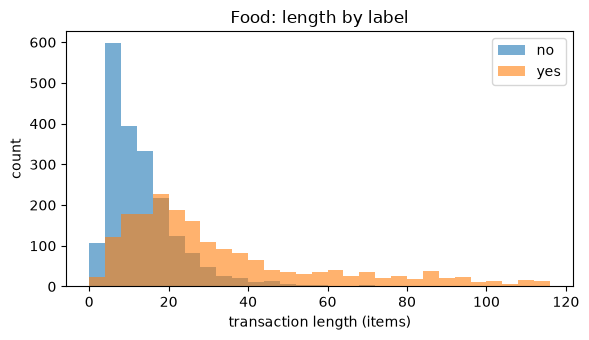

In [12]:
desc = pd.Series(food_len).groupby(food_y).describe()
len_tab = pd.DataFrame({
    "Nhãn": desc.index,
    "Số giỏ": desc["count"].astype(int).to_numpy(),
    "Độ dài TB": desc["mean"].to_numpy(),
    "Trung vị": desc["50%"].astype(int).to_numpy(),
    "Nhỏ nhất": desc["min"].astype(int).to_numpy(),
    "Lớn nhất": desc["max"].astype(int).to_numpy(),
})
display(nice(len_tab, digits=1, caption="Food: độ dài giỏ hàng theo nhãn"))

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.arange(0, 120, 4)
for lab in ["no", "yes"]:
    ax.hist(food_len[food_y == lab], bins=bins, alpha=0.6, label=lab)
ax.set_xlabel("transaction length (items)")
ax.set_ylabel("count")
ax.set_title("Food: length by label")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "food_length_by_label.png", dpi=150)
plt.show()

Khách `yes` mua nhiều món hơn hẳn khách `no`: độ dài trung vị là 25 so với 10. Nghĩa là riêng độ dài giỏ hàng đã mang nhiều thông tin về nhãn. Notebook 04 dùng độ dài làm một baseline (LENGTH-ONLY) và giải thích vì sao có hiện tượng này.

## 2. Food — lấy utility thật từ CSDL FoodMart

Mỗi dòng của `food.txt` là tập sản phẩm một khách đã mua. Ta gộp bảng `sales.csv` theo `customer_id` và so khớp từng giỏ với một khách. Utility của một item là `store_sales × 100` (đổi sang cent), cộng dồn qua mọi lượt mua của khách đó. Đây đúng là quy ước mà file `foodmart.txt` của SPMF dùng (xem mục 3).

In [13]:
sales = pd.read_csv(DATA / "foodmart_db" / "sales.csv")
sales["u"] = (sales["store_sales"] * 100).round().astype(int)
sales["promo"] = sales["promotion_id"].notna()

cust_items = sales.groupby("customer_id")["product_id"].apply(lambda s: frozenset(map(str, s)))
basket_to_cust = defaultdict(list)
for cid, items in cust_items.items():
    basket_to_cust[items].append(cid)

matched = [basket_to_cust.get(frozenset(d), []) for d in food_docs]
n_unique = sum(len(m) == 1 for m in matched)

cust_promo = sales.groupby("customer_id")["promo"].any()
food_cust = [m[0] for m in matched]
same_label = np.mean([(cust_promo[c] == (lab == "yes")) for c, lab in zip(food_cust, food_y)])

print(f"Giỏ khớp với đúng 1 khách hàng: {n_unique:,} / {len(food_docs):,}")
print(f"Nhãn 'yes' trùng với 'khách có mua hàng khuyến mãi': {same_label:.1%}")

Giỏ khớp với đúng 1 khách hàng: 4,000 / 4,000
Nhãn 'yes' trùng với 'khách có mua hàng khuyến mãi': 100.0%


Cả 4.000 giỏ đều khớp đúng một khách, và nhãn `yes` trùng 100% với việc khách có mua hàng khuyến mãi. Vậy `food.txt` chính là dữ liệu FoodMart gộp theo khách hàng, và ta lấy được utility thật cho nó.

In [14]:
cust_prod_u = sales.groupby(["customer_id", "product_id"])["u"].sum()
food_utility = []
for cid, doc in zip(food_cust, food_docs):
    items = list(dict.fromkeys(int(i) for i in doc))  # SPMF format needs distinct items
    food_utility.append((items, [int(cust_prod_u[(cid, i)]) for i in items]))
write_utility_db(PROCESSED / "food_utility.txt", food_utility)

food_tu = np.array([sum(u) for _, u in food_utility])
print("Đã ghi processed/food_utility.txt")
print(f"Transaction utility (cent): trung vị {np.median(food_tu):,.0f}, lớn nhất {food_tu.max():,}")

Đã ghi processed/food_utility.txt
Transaction utility (cent): trung vị 10,190, lớn nhất 190,790


Kiểm tra nhanh: khuyến mãi có làm thay đổi giá không? Nếu có, utility sẽ "lộ" nhãn và so sánh Hui2Vec với Trans2Vec trên Food sẽ không công bằng.

In [15]:
unit_price = sales["store_sales"] / sales["unit_sales"]
price_by_promo = unit_price.groupby([sales["product_id"], sales["promo"]]).mean().unstack()
ratio = (price_by_promo[True] / price_by_promo[False]).mean()
qty = sales.groupby("promo")["unit_sales"].mean()

nice(pd.DataFrame({
    "Chỉ số": ["Giá trung bình: có KM / không KM", "Số lượng TB mỗi dòng bán, không KM", "Số lượng TB mỗi dòng bán, có KM"],
    "Giá trị": [ratio, qty[False], qty[True]],
}), digits=3, caption="Khuyến mãi có làm đổi giá hoặc số lượng không?")

Chỉ số,Giá trị
Giá trung bình: có KM / không KM,1.000
"Số lượng TB mỗi dòng bán, không KM",3.090
"Số lượng TB mỗi dòng bán, có KM",3.089


Giá và số lượng trung bình như nhau dù có khuyến mãi hay không, nên utility không chứa trực tiếp thông tin về nhãn.

## 3. Foodmart utility — thống kê và gán nhãn

In [16]:
fm = read_utility_db(DATA / "utility" / "foodmart.txt")
fm_items = [t[0] for t in fm]
fm_tu = np.array([t[2] for t in fm])

nice(pd.DataFrame({
    "Chỉ số": ["Số giao dịch", "Số item phân biệt", "Độ dài trung bình",
               "Transaction utility: trung vị", "Transaction utility: lớn nhất"],
    "Giá trị": [f"{len(fm):,}", f"{len({i for t in fm_items for i in t}):,}",
                f"{np.mean([len(t) for t in fm_items]):.2f}", f"{np.median(fm_tu):,.0f}", f"{fm_tu.max():,}"],
}), caption="Foodmart utility: thống kê cơ bản")

Chỉ số,Giá trị
Số giao dịch,"4,141"
Số item phân biệt,"1,559"
Độ dài trung bình,4.42
Transaction utility: trung vị,"2,770"
Transaction utility: lớn nhất,"9,180"


Khớp với Bảng 5 của bài Hui2Vec: 4.141 giao dịch, 1.559 item, độ dài trung bình 4,4. Bài Hui2Vec ghi là có 2 lớp nhưng **không công bố nhãn**, nên ta phải tự định nghĩa.

**Nhãn chọn cho Foodmart: giỏ hàng giá trị cao.** Giao dịch có tổng utility (TU) ≥ trung vị được gán nhãn `high`, còn lại là `low`. Lý do chọn:

- Đơn giản, dễ giải thích, và hai lớp cân bằng 50/50.
- Đúng với tinh thần bài Hui2Vec: dự đoán giá trị của giỏ hàng từ các món trong giỏ.
- Mô hình chỉ thấy *các item* (Trans2Vec) hoặc *các item + HUI* (Hui2Vec), không thấy trực tiếp con số TU.

Cần lưu ý khi đọc kết quả: Hui2Vec dùng utility lúc khai thác HUI nên được lợi thế tự nhiên trên nhãn này.

In [17]:
median_tu = np.median(fm_tu)
fm_label = np.where(fm_tu >= median_tu, "high", "low")
pd.DataFrame({"tid": np.arange(len(fm)), "tu": fm_tu, "label": fm_label}).to_csv(PROCESSED / "foodmart_labels.csv", index=False)

print(f"Ngưỡng (trung vị TU): {median_tu:,.0f}")
print(f"Phân bố nhãn: {counts(fm_label)}")

Ngưỡng (trung vị TU): 2,770
Phân bố nhãn: high: 2,073 | low: 2,068


## 4. Chia train/test

Theo đúng hai bài báo:

- **Food:** code gốc của Trans2Vec lấy 3.200 dòng đầu làm train và 800 dòng cuối làm test (`use_train = "fix"`), không xáo trộn.
- **Foodmart:** bài Hui2Vec xáo trộn ngẫu nhiên rồi chia 3.313/828. Ta cố định `random_state=0` để mọi notebook dùng chung một cách chia.

In [18]:
from sklearn.model_selection import train_test_split

food_split = {"train": list(range(3200)), "test": list(range(3200, 4000))}
fm_train, fm_test = train_test_split(np.arange(len(fm)), test_size=828, random_state=0, shuffle=True)
fm_split = {"train": sorted(map(int, fm_train)), "test": sorted(map(int, fm_test))}

json.dump(food_split, open(PROCESSED / "food_split.json", "w"))
json.dump(fm_split, open(PROCESSED / "foodmart_split.json", "w"))

nice(pd.DataFrame({
    "Dataset": ["Food", "Foodmart"],
    "Train": [len(food_split["train"]), len(fm_split["train"])],
    "Test": [len(food_split["test"]), len(fm_split["test"])],
    "Nhãn trong tập test": [counts(food_y[food_split["test"]]), counts(fm_label[fm_split["test"]])],
}), caption="Cách chia train/test")

Dataset,Train,Test,Nhãn trong tập test
Food,"3,200",800,no: 402 | yes: 398
Foodmart,"3,313",828,high: 417 | low: 411


## Tóm tắt

| | Food | Foodmart utility |
|---|---|---|
| Giao dịch | 4.000 | 4.141 |
| Độ dài TB | 25,87 | 4,42 |
| Nhãn | coupon/khuyến mãi (nhãn gốc của bài) | giỏ giá trị cao: TU ≥ median (tự định nghĩa) |
| Utility | thật, lấy từ `sales.csv` | thật, có sẵn trong file |
| Train/test | 3.200 / 800 (cố định) | 3.313 / 828 (xáo trộn, seed 0) |

File sinh ra: `food_utility.txt`, `foodmart_labels.csv`, `food_split.json`, `foodmart_split.json`.